# ConnectaTel | Uso móvil y segmentación de clientes

**Proyecto 6 · TripleTen · Análisis exploratorio**  
**Período de uso:** 1 de enero a 30 de junio de 2024 · **Mercados:** México y Colombia

ConnectaTel quiere conocer cómo usan sus clientes las llamadas y los mensajes, qué casos merecen revisión y dónde hay oportunidades para mejorar sus planes. El análisis parte de eventos y cuentas, pasa por un control de calidad y termina con segmentos y recomendaciones. La unidad de comparación es la **cuenta de usuario**, no el evento. Para contrastar el uso con los beneficios de un plan, la unidad es la **cuenta-mes**.

El notebook conserva las salidas. Para repetir el análisis, coloca los tres CSV del curso en `data/` y ejecuta todas las celdas. El README incluye las fuentes y los pasos de ejecución.

## 1. Carga y revisión de fuentes

`plans.csv` es el catálogo de beneficios y tarifas. `users_latam.csv` es el padrón de usuarios y planes. `usage.csv` registra llamadas o mensajes, con la duración o longitud que corresponda. Los nombres personales no intervienen en el análisis ni aparecen en sus salidas.

In [1]:
import hashlib
import os
from decimal import Decimal, InvalidOperation
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

%matplotlib inline

START = pd.Timestamp('2024-01-01')
END = pd.Timestamp('2024-06-30')
FILE_KEYS = {'plans.csv': 'plan_name', 'users_latam.csv': 'user_id', 'usage.csv': 'id'}
configured = os.getenv('CONNECTATEL_DATA_DIR')
locations = [Path(configured)] if configured else [Path('data'), Path('/datasets'), Path('.')]
DATA_DIR = next((folder for folder in locations if all((folder / name).is_file() for name in FILE_KEYS)),
                locations[0])
TIMESTAMP_FORMAT = '%Y-%m-%d %H:%M:%S.%f'
missing_files = [name for name in FILE_KEYS if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Faltan en {DATA_DIR}: {", ".join(missing_files)}. Consulta el README.')

plans_raw = pd.read_csv(DATA_DIR / 'plans.csv', dtype={'plan_name': 'string'})
users_raw = pd.read_csv(DATA_DIR / 'users_latam.csv', dtype={'user_id': 'string', 'churn_date': 'string'})
usage_raw = pd.read_csv(DATA_DIR / 'usage.csv', dtype={'id': 'string', 'user_id': 'string'})
raw = dict(zip(FILE_KEYS, (plans_raw, users_raw, usage_raw)))

schema = {
    'plans.csv': {'plan_name', 'messages_included', 'gb_per_month', 'minutes_included', 'usd_monthly_pay',
                  'usd_per_gb', 'usd_per_message', 'usd_per_minute'},
    'users_latam.csv': {'user_id', 'age', 'city', 'reg_date', 'plan', 'churn_date'},
    'usage.csv': {'id', 'user_id', 'type', 'date', 'duration', 'length'},
}
for name, frame in raw.items():
    if absent := schema[name] - set(frame.columns):
        raise ValueError(f'{name}: faltan las columnas {sorted(absent)}')

display(pd.DataFrame([
    {'archivo': name, 'filas': len(frame), 'columnas': frame.shape[1],
     'duplicados exactos': int(frame.duplicated().sum()),
     'clave nula': int(frame[FILE_KEYS[name]].isna().sum()),
     'clave repetida': int(frame[FILE_KEYS[name]].dropna().duplicated().sum()),
     'SHA-256': hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()}
    for name, frame in raw.items()
]).set_index('archivo'))

columns = []
for name, frame in raw.items():
    profile = pd.DataFrame({'tipo inicial': frame.dtypes.astype(str), 'nulos': frame.isna().sum(),
                            '% nulo': 100 * frame.isna().mean(), 'distintos': frame.nunique()})
    columns.append(profile.assign(archivo=name).rename_axis('columna').reset_index())
display(pd.concat(columns, ignore_index=True).set_index(['archivo', 'columna']).round(2))

for name, frame in raw.items():
    print(f'{name} · estructura original')
    frame.info()
display(plans_raw.head())
display(users_raw[['plan']].head(), usage_raw[['type']].head())
print('Las vistas previas de usuarios y eventos muestran solo categorías generales.')

,filas,columnas,duplicados exactos,clave nula,clave repetida,SHA-256
archivo,,,,,,
plans.csv,2,8,0,0,0,bc88ab0606277e2875075924a68892f31f9a2b7c16522f...
users_latam.csv,4000,8,0,0,0,1def605b2b2a23f03d19dddb4ad184335dc8c89724f882...
usage.csv,40000,6,0,0,0,9ae3deba34b1abf503174ef47c571ed1ec41b7bee6b94a...


tipo inicial  nulos  % nulo  distintos
archivo         columna                                                 
plans.csv       plan_name               string      0    0.00          2
                messages_included        int64      0    0.00          2
                gb_per_month             int64      0    0.00          2
                minutes_included         int64      0    0.00          2
                usd_monthly_pay          int64      0    0.00          2
                usd_per_gb             float64      0    0.00          2
                usd_per_message        float64      0    0.00          2
                usd_per_minute         float64      0    0.00          2
users_latam.csv user_id                 string      0    0.00       4000
                first_name                 str      0    0.00          6
                last_name                  str      0    0.00          5
                age                      int64      0    0.00         63
                city                       str    469   11.72          7
                reg_date                   str      0    0.00       3961
                plan                       str      0    0.00          2
                churn_date              string   3534   88.35        197
usage.csv       id                      string      0    0.00      40000
                user_id                 string      0    0.00       3999
                type                       str      0    0.00          2
                date                       str     50    0.12      39950
                duration               float64  22076   55.19       2090
                length                 float64  17896   44.74        123

plans.csv · estructura original
<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      string 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), string(1)
memory usage: 260.0 bytes
users_latam.csv · estructura original
<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   string
 1   first_name  4000 non-null   str   
 2   last_name   4000 non-null   str   


,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


,plan
0,Basico
1,Basico
2,Basico
3,Premium
4,Basico


,type
0,call
1,text
2,text
3,call
4,call


Las vistas previas de usuarios y eventos muestran solo categorías generales.


## 2. Calidad y reglas de limpieza

### 2.1 Diagnóstico original

Los nulos de ciudad requieren conservar la categoría geográfica desconocida. Una baja vacía se interpreta como ausencia de una baja registrada. Un evento sin fecha no se puede ubicar en el período de análisis. La ausencia de duración o longitud depende casi por completo del tipo de evento, como muestra la tabla. Es un faltante estructural para el servicio al que el campo no aplica.

In [2]:
for label, col in [('Edad original', users_raw['age']), ('Duración original', usage_raw['duration']),
                   ('Longitud original', usage_raw['length'])]:
    display(col.describe().rename(label).to_frame().round(2))

for col in ['city', 'plan']:
    display(users_raw[col].value_counts(dropna=False).rename('usuarios').to_frame())
display(usage_raw['type'].value_counts(dropna=False).rename('eventos').to_frame())

for label, col in [('Año de registro', users_raw['reg_date']), ('Año de actividad', usage_raw['date'])]:
    dates = pd.to_datetime(col, format=TIMESTAMP_FORMAT, errors='coerce')
    display(dates.dt.year.value_counts(dropna=False).sort_index().rename(label).to_frame())

null_by_type = usage_raw.groupby('type')[['duration', 'length']].agg(lambda col: 100 * col.isna().mean())
display(null_by_type.rename(columns={'duration': '% duración nula', 'length': '% longitud nula'}).round(2))

,Edad original
count,4000.00
mean,33.74
std,123.23
min,-999.00
25%,32.00
50%,47.00
75%,63.00
max,79.00


,Duración original
count,17924.00
mean,5.20
std,6.84
min,0.00
25%,1.44
50%,3.50
75%,6.99
max,120.00


,Longitud original
count,22104.00
mean,52.13
std,56.61
min,0.00
25%,37.00
50%,50.00
75%,64.00
max,1490.00


,usuarios
city,
Bogotá,808
CDMX,730
Medellín,616
NaN,469
GDL,450
Cali,424
MTY,407
?,96


,usuarios
plan,
Basico,2595
Premium,1405


,eventos
type,
text,22092
call,17908


,Año de registro
reg_date,
2022,1314
2023,1316
2024,1330
2026,40


,Año de actividad
date,
2024.0,39950
NaN,50


,% duración nula,% longitud nula
type,,
call,0.00,99.93
text,99.93,0.00


### 2.2 Decisiones de limpieza

| Hallazgo | Regla aplicada |
|---|---|
| Edad `-999` o fuera de 18–100 años | Se marca la edad inválida y se imputa la mediana de las edades válidas para construir los grupos solicitados. |
| Ciudad vacía o `?` | Pasa a faltante. El país se deriva de las seis ciudades conocidas. El grupo `Sin país` se mantiene separado. |
| Cancelación vacía o escrita en notación científica con coma | Una celda vacía significa que no consta una baja. Las fechas numéricas se interpretan como nanosegundos desde 1970 con `Decimal` y se comparan a nivel de día porque el archivo muestra valores redondeados. Una baja anterior al alta queda marcada como inconsistente y no se usa como límite de exposición. |
| Duración de un mensaje o longitud de una llamada | Son campos no aplicables. Se dejan vacíos, incluso si traen un valor. El evento se conserva si cumple las demás reglas. |
| Duración o longitud válida igual a cero | Se conserva y se cuenta como actividad registrada. Puede representar un intento o una captura incompleta. Los negativos y longitudes no enteras se excluyen de esa métrica. |
| Evento sin fecha o fuera del período de alta y baja | No entra al análisis principal. Se cuantifica por separado y se compara con una versión que conserva eventos fechados sin exigir coherencia con el alta y la baja. |

Las fechas no contienen zona horaria. La elegibilidad se compara por día, inclusive. Los eventos extremos con estructura válida se conservan y se marcan para revisión. Se asume que `duration` está en minutos, por su relación con el catálogo. `length` se usa como longitud registrada, en caracteres, y no como cantidad de SMS facturables.

In [3]:
def unique_rows(frame, key, label):
    frame = frame.drop_duplicates().copy()
    frame[key] = frame[key].astype('string').str.strip().replace('', pd.NA)
    if frame[key].isna().any() or not frame[key].is_unique:
        raise ValueError(f'{label}: la clave {key} no identifica de forma única cada fila')
    return frame


def date_iso(col):
    return pd.to_datetime(col, format=TIMESTAMP_FORMAT, errors='coerce')


def parse_churn(value):
    if pd.isna(value) or not str(value).strip():
        return pd.NaT
    value = str(value).strip()
    if 'e+' in value.lower() or value.isdecimal():
        try:
            return pd.to_datetime(int(Decimal(value.replace(',', '.'))), unit='ns', errors='coerce')
        except (InvalidOperation, ValueError, OverflowError):
            return pd.NaT
    return pd.to_datetime(value, errors='coerce')


def number(col):
    values = pd.to_numeric(col, errors='coerce')
    return values.where(np.isfinite(values))


plans = unique_rows(plans_raw, 'plan_name', 'planes')
plans['plan_key'] = plans['plan_name'].str.casefold()
assert plans['plan_key'].is_unique
plans['plan_name'] = plans['plan_name'].replace({'Basico': 'Básico'})
for col in sorted(schema['plans.csv'] - {'plan_name'}):
    plans[col] = number(plans[col])
    if not plans[col].ge(0).all() or plans[col].isna().any():
        raise ValueError(f'El catálogo contiene valores faltantes o inválidos en {col}')

city_country = {'bogotá': ('Bogotá', 'Colombia'), 'medellín': ('Medellín', 'Colombia'),
                'cali': ('Cali', 'Colombia'), 'cdmx': ('Ciudad de México', 'México'),
                'gdl': ('Guadalajara', 'México'), 'mty': ('Monterrey', 'México')}
users = unique_rows(users_raw, 'user_id', 'usuarios')[list(sorted(schema['users_latam.csv']))].copy()
age_raw = number(users['age'])
valid_age = age_raw.where(age_raw.between(18, 100))
age_median = valid_age.median()
users['age_imputada'] = valid_age.isna()
users['age'] = valid_age.fillna(age_median)
city_key = users['city'].astype('string').str.strip().str.casefold()
city_missing_original = int(users['city'].isna().sum())
users['city'] = users['city'].mask(city_key.eq('?').fillna(False), pd.NA)
users['city_clean'] = city_key.map({k: v[0] for k, v in city_country.items()})
users['country'] = city_key.map({k: v[1] for k, v in city_country.items()}).fillna('Sin país')
reg_read = date_iso(users['reg_date']).dt.normalize()
reg_out_of_range = reg_read.dt.year.gt(2024)
users['reg_day'] = reg_read.mask(reg_out_of_range)
users['reg_out_of_range'] = reg_out_of_range
churn_read = pd.to_datetime(users['churn_date'].map(parse_churn), errors='coerce').dt.normalize()
churn_conflict = churn_read.lt(users['reg_day'])
churn_parse_fail = (users['churn_date'].notna() & churn_read.isna()).sum()
users['churn_day'] = churn_read.mask(churn_conflict)
users['plan_key'] = users['plan'].astype('string').str.strip().str.casefold()
users = users.merge(plans, on='plan_key', how='left', validate='many_to_one', indicator='plan_match')

usage = unique_rows(usage_raw, 'id', 'eventos')
usage['user_id'] = usage['user_id'].str.strip()
usage['type'] = usage['type'].astype('string').str.strip().str.casefold()
usage['event_time'] = date_iso(usage['date'])
usage['event_day'] = usage['event_time'].dt.normalize()
is_call = usage['type'].eq('call').fillna(False)
is_text = usage['type'].eq('text').fillna(False)
duration = number(usage['duration'])
length = number(usage['length'])
usage['call_minutes'] = duration.where(is_call & duration.ge(0))
usage['text_chars'] = length.where(is_text & length.ge(0) & length.mod(1).eq(0))

quality = {
    'Edad centinela -999': age_raw.eq(-999).sum(),
    'Edad imputada con la mediana válida': users['age_imputada'].sum(),
    'Ciudad vacía en origen': city_missing_original,
    'Ciudad centinela ?': city_key.eq('?').sum(),
    'País sin determinar': users['country'].eq('Sin país').sum(),
    'Alta posterior al período de uso': reg_read.gt(END).sum(),
    'Alta posterior al año 2024 marcada como nula': reg_out_of_range.sum(),
    'Alta no interpretable en origen': reg_read.isna().sum(),
    'Baja sin registro': users['churn_date'].isna().sum(),
    'Baja numérica en notación científica': users['churn_date'].str.contains('E+', case=False, regex=False).sum(),
    'Baja informada que no se pudo interpretar': churn_parse_fail,
    'Baja anterior al alta': churn_conflict.sum(),
    'Usuarios con plan no encontrado': users['plan_match'].ne('both').sum(),
    'Evento sin fecha interpretable': usage['event_day'].isna().sum(),
    'Duración informada en mensajes': (is_text & usage['duration'].notna()).sum(),
    'Longitud informada en llamadas': (is_call & usage['length'].notna()).sum(),
    'Llamadas con duración faltante o inválida': (is_call & usage['call_minutes'].isna()).sum(),
    'Mensajes con longitud faltante o inválida': (is_text & usage['text_chars'].isna()).sum(),
    'Llamadas de duración cero': usage['call_minutes'].eq(0).sum(),
    'Mensajes de longitud cero': usage['text_chars'].eq(0).sum(),
}
display(pd.Series(quality, name='registros').astype(int).to_frame())
print(f'Mediana válida usada para imputar la edad: {age_median:.0f} años.')
print(f'Primera actividad fechada: {usage["event_time"].min()} · última: {usage["event_time"].max()}')

,registros
Edad centinela -999,55
Edad imputada con la mediana válida,55
Ciudad vacía en origen,469
Ciudad centinela ?,96
País sin determinar,565
Alta posterior al período de uso,708
Alta posterior al año 2024 marcada como nula,40
Alta no interpretable en origen,0
Baja sin registro,3534
Baja numérica en notación científica,466


Mediana válida usada para imputar la edad: 48 años.
Primera actividad fechada: 2024-01-01 00:00:00 · última: 2024-06-30 00:00:00


## 3. Integración y universo de análisis

El catálogo se une al padrón por plan y el padrón a la actividad por `user_id`, con validación de cardinalidad en ambas uniones. Los motivos de exclusión se asignan en orden para que cada evento cuente una sola vez. El perfil incluye cuentas elegibles con cero eventos válidos. Sus ceros significan ausencia de actividad observada bajo estas reglas.

Se calcula la exposición por cuenta en días del período. Para comparar segmentos se usan tasas por 30 días entre cuentas con al menos 30 días de exposición. Las tasas son resúmenes de actividad observada, no estimaciones de facturación.

In [4]:
joined = usage.merge(users[['user_id', 'reg_day', 'reg_out_of_range', 'churn_day']],
                     on='user_id', how='left', validate='many_to_one', indicator='user_match')
assert len(joined) == len(usage)

event_checks = {
    'Usuario sin correspondencia': joined['user_match'].ne('both'),
    'Tipo distinto de call/text': ~joined['type'].isin(['call', 'text']),
    'Fecha faltante o inválida': joined['event_day'].isna(),
    'Evento fuera del semestre': ~joined['event_day'].between(START, END),
    'Alta posterior a 2024': joined['reg_out_of_range'],
    'Alta faltante o inválida': joined['reg_day'].isna(),
    'Evento anterior al alta': joined['event_day'].lt(joined['reg_day']),
    'Evento posterior a la baja': joined['event_day'].gt(joined['churn_day']),
}
joined['decision'] = 'Conservar'
for reason, mask in event_checks.items():
    joined.loc[mask.fillna(False) & joined['decision'].eq('Conservar'), 'decision'] = reason

audit = joined['decision'].value_counts().reindex(['Conservar', *event_checks], fill_value=0).rename('eventos').to_frame()
audit['% de eventos'] = 100 * audit['eventos'] / len(joined)
display(audit.round(2))
events = joined.loc[joined['decision'].eq('Conservar')].copy()
calendar_events = joined.loc[
    joined['user_match'].eq('both') & joined['type'].isin(['call', 'text']) & joined['event_day'].between(START, END)
].copy()

cohort = users.loc[users['reg_day'].le(END) & (users['churn_day'].isna() | users['churn_day'].ge(START))].copy()
cohort['observed_start'] = cohort['reg_day'].clip(lower=START)
cohort['observed_end'] = cohort['churn_day'].fillna(END).clip(upper=END)
cohort['observed_days'] = (cohort['observed_end'] - cohort['observed_start']).dt.days + 1
assert cohort['observed_days'].gt(0).all()
assert events['user_id'].isin(cohort['user_id']).all()


def summarize_events(frame, keys):
    frame = frame.assign(llamadas=frame['type'].eq('call').astype(int),
                         mensajes=frame['type'].eq('text').astype(int),
                         llamadas_con_medida=frame['call_minutes'].notna().astype(int),
                         mensajes_con_medida=frame['text_chars'].notna().astype(int))
    return frame.groupby(keys, observed=True).agg(
        llamadas=('llamadas', 'sum'), mensajes=('mensajes', 'sum'),
        minutos=('call_minutes', 'sum'), caracteres=('text_chars', 'sum'),
        llamadas_con_medida=('llamadas_con_medida', 'sum'), mensajes_con_medida=('mensajes_con_medida', 'sum'),
    )


metrics = ['llamadas', 'mensajes', 'minutos', 'caracteres', 'llamadas_con_medida', 'mensajes_con_medida']
account_totals = summarize_events(events, ['user_id'])
profiles = cohort.merge(account_totals, on='user_id', how='left', validate='one_to_one')
profiles[metrics] = profiles[metrics].fillna(0)
profiles['eventos'] = profiles['llamadas'] + profiles['mensajes']
for col in ['llamadas', 'mensajes', 'minutos', 'caracteres', 'eventos']:
    profiles[f'{col}_30d'] = 30 * profiles[col] / profiles['observed_days']

profiles['edad_grupo'] = pd.cut(profiles['age'], [17, 29, 44, 59, 100], labels=['18–29', '30–44', '45–59', '60+'])
profiles['edad_grupo'] = profiles['edad_grupo'].astype('string').fillna('Sin edad')
profiles['plan_label'] = profiles['plan_name'].fillna('Sin plan')

assert profiles['user_id'].is_unique and len(profiles) == len(cohort)
assert int(profiles['eventos'].sum()) == len(events)
assert np.isclose(profiles['minutos'].sum(), events['call_minutes'].sum())
assert np.isclose(profiles['caracteres'].sum(), events['text_chars'].sum())
assert int(audit['eventos'].sum()) == len(usage)
assert events.loc[events['type'].eq('text'), 'call_minutes'].isna().all()
assert events.loc[events['type'].eq('call'), 'text_chars'].isna().all()

stable = profiles.loc[profiles['observed_days'].ge(30)].copy()
print(f'{len(profiles):,} cuentas elegibles, {len(stable):,} con al menos 30 días y '
      f'{profiles["eventos"].eq(0).sum():,} sin eventos conservados.')

loose_totals = summarize_events(calendar_events, ['user_id']).reindex(stable['user_id'], fill_value=0)
strict_totals = stable.set_index('user_id')
sensitivity = pd.DataFrame({
    'solo calendario': [loose_totals['llamadas'].sum(), loose_totals['mensajes'].sum(),
                        loose_totals['llamadas'].median(), loose_totals['mensajes'].median()],
    'con reglas de alta y baja': [strict_totals['llamadas'].sum(), strict_totals['mensajes'].sum(),
                                  strict_totals['llamadas'].median(), strict_totals['mensajes'].median()],
}, index=['llamadas totales', 'mensajes totales', 'mediana de llamadas por cuenta', 'mediana de mensajes por cuenta'])
display(sensitivity.round(2))

,eventos,% de eventos
decision,,
Conservar,29482,73.70
Usuario sin correspondencia,0,0.00
Tipo distinto de call/text,0,0.00
Fecha faltante o inválida,50,0.12
Evento fuera del semestre,0,0.00
Alta posterior a 2024,373,0.93
Alta faltante o inválida,0,0.00
Evento anterior al alta,10058,25.14
Evento posterior a la baja,37,0.09


3,292 cuentas elegibles, 3,185 con al menos 30 días y 71 sin eventos conservados.


,solo calendario,con reglas de alta y baja
llamadas totales,14230.0,13125.0
mensajes totales,17539.0,16278.0
mediana de llamadas por cuenta,4.0,4.0
mediana de mensajes por cuenta,5.0,5.0


## 4. Estadísticas descriptivas

El perfil por usuario suma llamadas, mensajes y minutos del período. Para cada métrica se muestran la media, los cuartiles y los extremos. El análisis posterior usa tasas por 30 días cuando necesita comparar cuentas con distinta exposición.

In [5]:
def frequencies(frame, columns):
    results = []
    for col in columns:
        counts = frame[col].value_counts(dropna=False)
        table = counts.rename('cuentas').rename_axis('categoría').reset_index()
        table['%'] = 100 * table['cuentas'] / len(frame)
        results.append(table.assign(variable=col))
    return pd.concat(results, ignore_index=True).set_index(['variable', 'categoría'])


user_profile = profiles[['user_id', 'age', 'age_imputada', 'country', 'plan_label', 'mensajes',
                         'llamadas', 'minutos']].rename(columns={
    'plan_label': 'plan', 'mensajes': 'cant_mensajes',
    'llamadas': 'cant_llamadas', 'minutos': 'cant_minutos_llamada',
})
uso_vars = {'age': 'Edad (años)', 'cant_mensajes': 'Mensajes por usuario',
            'cant_llamadas': 'Llamadas por usuario', 'cant_minutos_llamada': 'Minutos por usuario'}
display(user_profile[list(uso_vars)].describe(percentiles=[.25, .50, .75, .95, .99]).T.round(2))
display(frequencies(user_profile, ['plan', 'country']).round(2))
display(user_profile.groupby('plan', observed=True)[list(uso_vars)].median().round(2))
event_summary = events[['call_minutes', 'text_chars']].describe(percentiles=[.25, .5, .75, .95, .99]).T
display(event_summary.rename(index={'call_minutes': 'Duración de llamada (min)', 'text_chars': 'Longitud de mensaje'}).round(2))
display(stable[['llamadas_30d', 'mensajes_30d', 'minutos_30d', 'eventos_30d']]
        .describe(percentiles=[.25, .5, .75, .95, .99]).T.round(2))

,count,mean,std,min,25%,50%,75%,95%,99%,max
age,3292.0,48.11,17.66,18.0,33.00,48.00,63.00,76.00,79.00,79.00
cant_mensajes,3292.0,4.96,2.60,0.0,3.00,5.00,7.00,9.00,11.00,17.00
cant_llamadas,3292.0,4.00,2.29,0.0,2.00,4.00,5.00,8.00,10.00,15.00
cant_minutos_llamada,3292.0,20.28,16.33,0.0,8.67,17.52,28.46,48.57,71.03,153.06


cuentas      %
variable categoría                
plan     Básico        2136  64.88
         Premium       1156  35.12
country  Colombia      1523  46.26
         México        1305  39.64
         Sin país       464  14.09

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
plan,,,,
Básico,48.0,5.0,4.0,16.98
Premium,48.0,5.0,4.0,18.30


,count,mean,std,min,25%,50%,75%,95%,99%,max
Duración de llamada (min),13157.0,5.07,5.80,0.0,1.44,3.51,6.95,15.01,23.05,120.0
Longitud de mensaje,16325.0,51.14,45.26,0.0,36.00,50.00,64.00,83.00,97.00,1490.0


,count,mean,std,min,25%,50%,75%,95%,99%,max
llamadas_30d,3185.0,0.73,0.39,0.0,0.49,0.66,0.99,1.40,1.79,3.62
mensajes_30d,3185.0,0.91,0.42,0.0,0.66,0.82,1.15,1.65,2.06,2.90
minutos_30d,3185.0,3.72,2.86,0.0,1.70,3.19,5.08,8.61,12.83,25.23
eventos_30d,3185.0,1.64,0.57,0.0,1.32,1.65,1.98,2.64,3.13,5.16


## 5. Distribuciones y valores atípicos

El IQR marca observaciones más allá de 1,5 rangos intercuartílicos desde cada cuartil. El puntaje Z marca observaciones a más de tres desviaciones estándar de la media en valor absoluto. Una marca inicia una revisión, ya que una llamada larga puede ser legítima. La decisión es conservar los extremos con estructura válida, separar los errores de calidad confirmados y evitar imputar medidas de uso faltantes.

Los histogramas por plan usan porcentajes dentro de cada plan para comparar sus formas. Los histogramas por evento muestran hasta el percentil 99 para facilitar la lectura. Los boxplots incluyen los valores extremos.

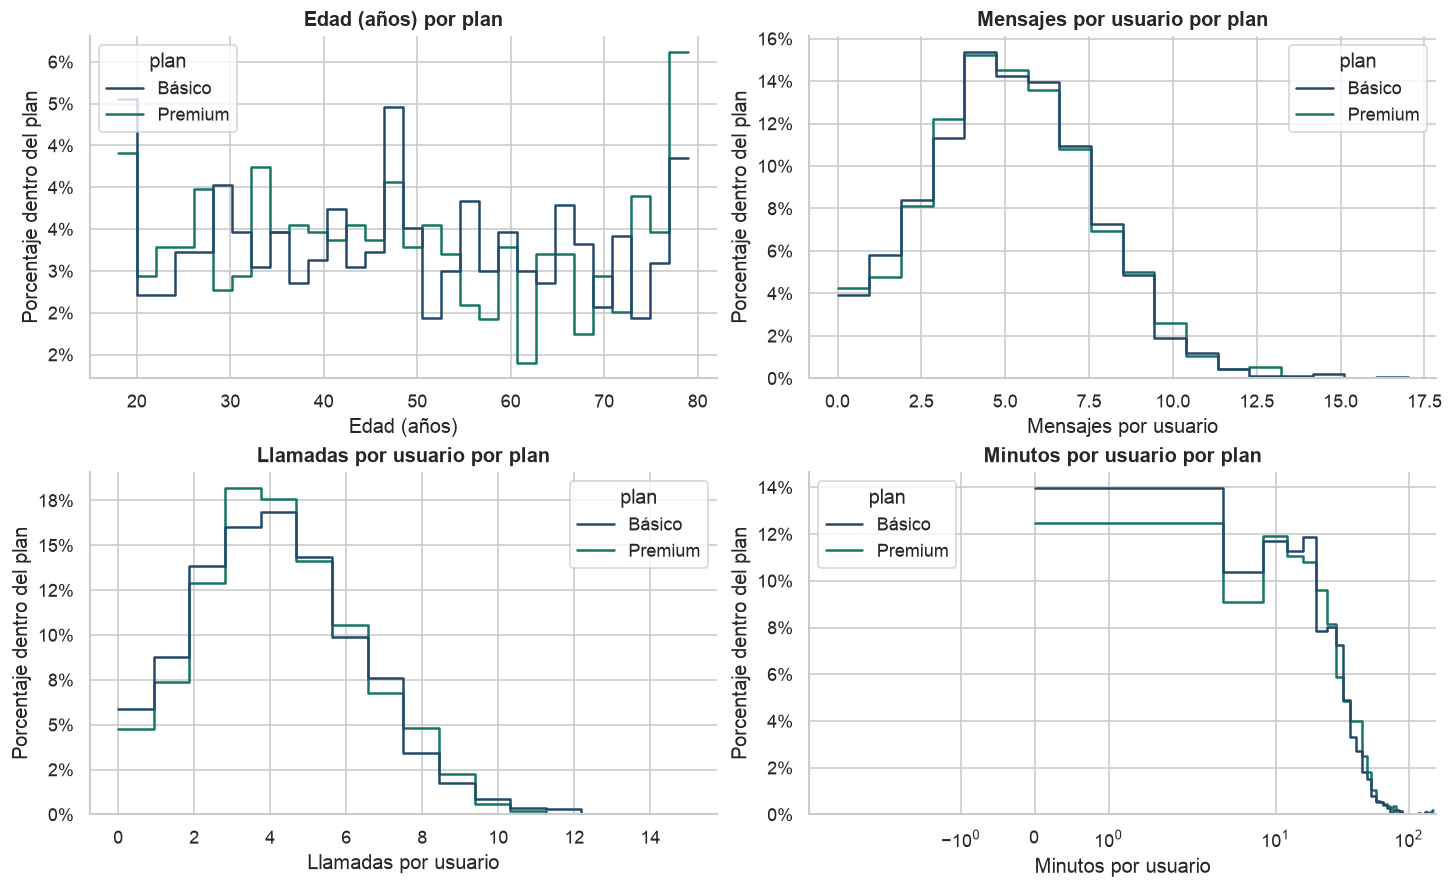

**Edad (años).** Básico, mediana 48.00, media 48.09, poco sesgo. Premium, mediana 48.00, media 48.16, poco sesgo.

**Mensajes por usuario.** Básico, mediana 5.00, media 4.95, poco sesgo. Premium, mediana 5.00, media 4.98, poco sesgo.

**Llamadas por usuario.** Básico, mediana 4.00, media 3.96, poco sesgo. Premium, mediana 4.00, media 4.06, poco sesgo.

**Minutos por usuario.** Básico, mediana 16.98, media 19.79, sesgo a la derecha. Premium, mediana 18.30, media 21.17, sesgo a la derecha.

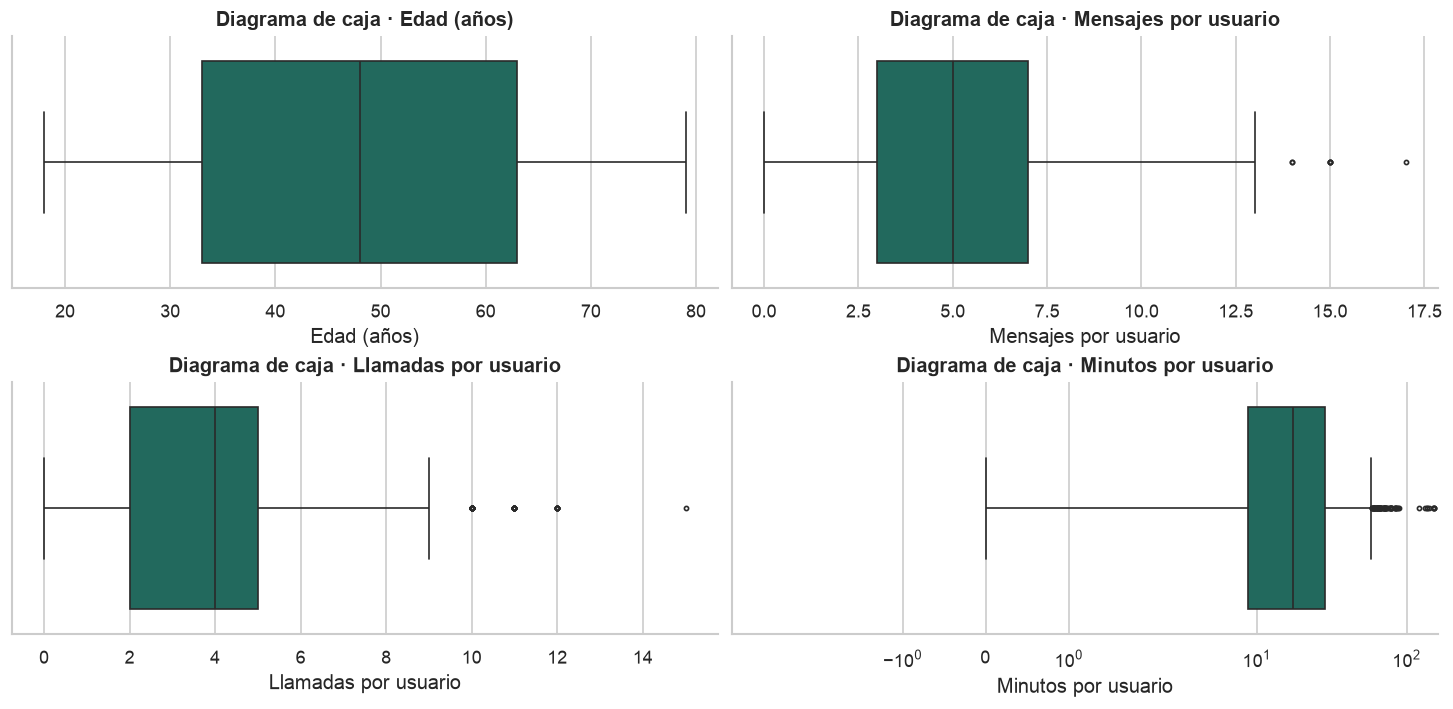

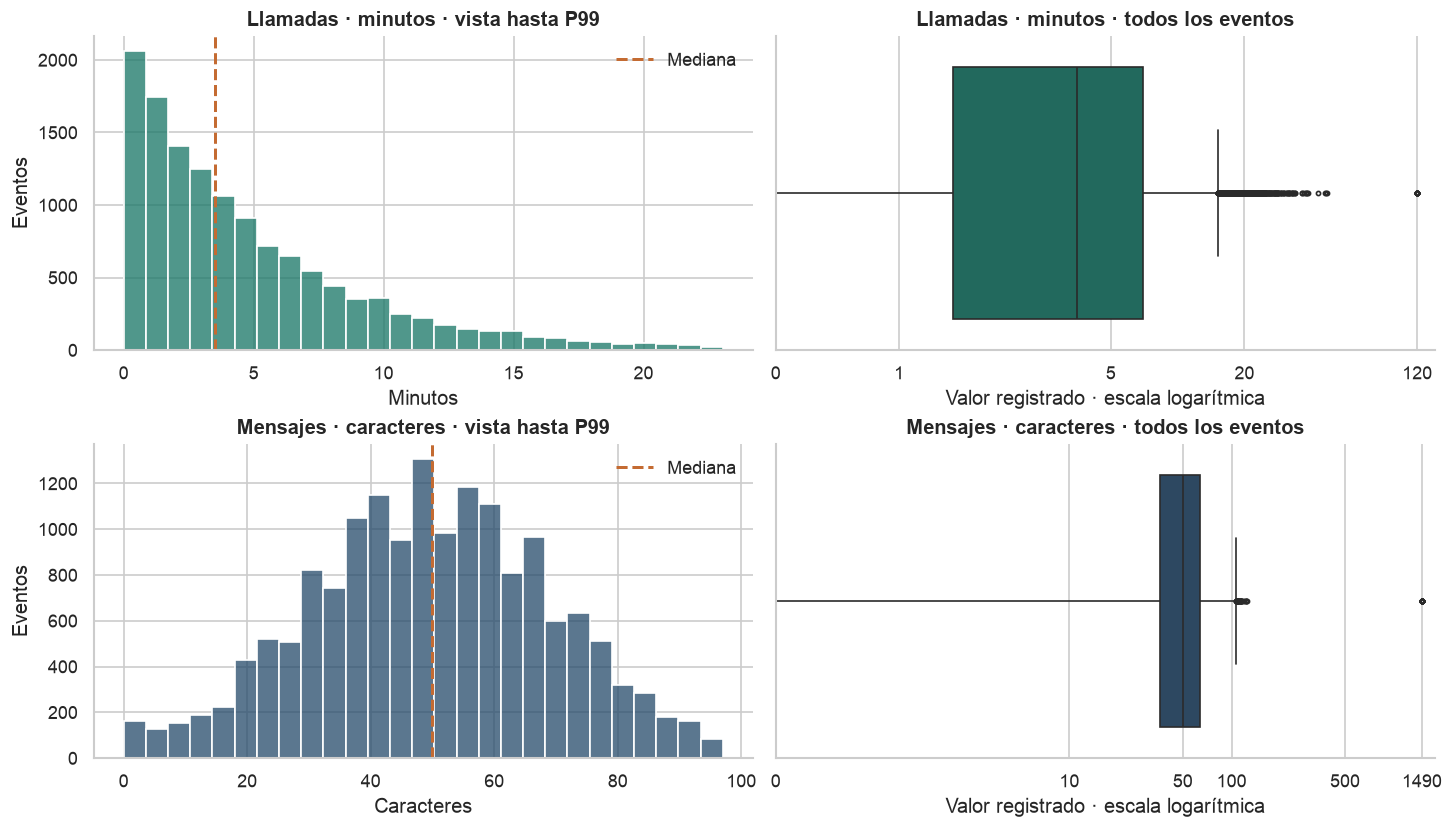

In [6]:
TEAL, NAVY, AMBER, SLATE = '#167565', '#24496A', '#C46B32', '#607386'
sns.set_theme(style='whitegrid', context='notebook', rc={'figure.dpi': 120, 'axes.titleweight': 'bold'})

colors = {'Básico': NAVY, 'Premium': TEAL, 'Sin plan': SLATE}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.3), constrained_layout=True)
for ax, (column, label) in zip(axes.flat, uso_vars.items()):
    data = user_profile[column]
    bins = min(30, int(data.max() - data.min()) + 1) if column != 'cant_minutos_llamada' else 38
    sns.histplot(data=user_profile, x=column, hue='plan', palette=colors, stat='probability',
                 common_norm=False, element='step', fill=False, bins=bins, ax=ax)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    if column == 'cant_minutos_llamada':
        ax.set_xscale('symlog')
    ax.set(title=f'{label} por plan', xlabel=label, ylabel='Porcentaje dentro del plan')
sns.despine(fig=fig)
plt.show()

comparison = user_profile.groupby('plan', observed=True)[list(uso_vars)].agg(['mean', 'median', 'skew'])
for column, label in uso_vars.items():
    parts = []
    for plan, row in comparison[column].iterrows():
        shape = ('sesgo a la derecha' if row['skew'] > .5 else
                 'sesgo a la izquierda' if row['skew'] < -.5 else 'poco sesgo')
        parts.append(f"{plan}, mediana {row['median']:.2f}, media {row['mean']:.2f}, {shape}")
    display(Markdown(f'**{label}.** ' + '. '.join(parts) + '.'))

fig, axes = plt.subplots(2, 2, figsize=(12, 5.8), constrained_layout=True)
for ax, (column, label) in zip(axes.flat, uso_vars.items()):
    sns.boxplot(data=user_profile, x=column, color=TEAL, fliersize=2.5, ax=ax)
    if column == 'cant_minutos_llamada':
        ax.set_xscale('symlog')
    ax.set(title=f'Diagrama de caja · {label}', xlabel=label)
sns.despine(fig=fig)
plt.show()

sources_plot = [(events['call_minutes'].dropna(), 'Llamadas · minutos', TEAL, [0, 1, 5, 20, 120]),
                (events['text_chars'].dropna(), 'Mensajes · caracteres', NAVY, [0, 10, 50, 100, 500, 1490])]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), constrained_layout=True)
for row, (series, label, color, ticks) in enumerate(sources_plot):
    p99 = series.quantile(.99)
    central = series.loc[series.le(p99)]
    sns.histplot(x=central, bins=27, ax=axes[row, 0], color=color, edgecolor='white')
    axes[row, 0].set(title=f'{label} · vista hasta P99', xlabel=label.split(' · ')[1].capitalize(), ylabel='Eventos')
    axes[row, 0].axvline(series.median(), color=AMBER, linestyle='--', linewidth=1.8, label='Mediana')
    axes[row, 0].legend(frameon=False, loc='upper right')
    sns.boxplot(x=series, ax=axes[row, 1], color=color, fliersize=2.5)
    axes[row, 1].set_xscale('symlog')
    axes[row, 1].set_xticks(ticks)
    axes[row, 1].set_xticklabels([str(x) for x in ticks])
    axes[row, 1].set(title=f'{label} · todos los eventos', xlabel='Valor registrado · escala logarítmica', ylabel='')
    axes[row, 1].set_xlim(0, max(ticks[-1], series.max()) * 1.2)
sns.despine(fig=fig, left=False)
plt.show()

In [7]:
def outlier_checks(series):
    values = series.dropna()
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask_iqr = values.lt(lower) | values.gt(upper)
    std = values.std()
    mask_z = ((values - values.mean()) / std).abs().gt(3) if pd.notna(std) and std > 0 else values.ne(values)
    return {'n': len(values), 'límite inferior IQR': lower, 'límite superior IQR': upper,
            'IQR': int(mask_iqr.sum()), 'Z': int(mask_z.sum()), 'ambos': int((mask_iqr & mask_z).sum()),
            '% IQR': 100 * mask_iqr.mean(), '% Z': 100 * mask_z.mean()}, mask_iqr, mask_z


limits_for_profile = pd.DataFrame({name: outlier_checks(user_profile[column])[0]
                                  for column, name in uso_vars.items()}).T
display(limits_for_profile[['n', 'límite inferior IQR', 'límite superior IQR', 'IQR', '% IQR']].round(2))
for label, row in limits_for_profile.iterrows():
    count = int(row['IQR'])
    decision = 'Se conservan y se marcan para revisión.' if count else 'Se conserva la distribución completa.'
    print(f'{label} · {count} valores fuera de los límites IQR. {decision}')

to_check = {'Duración por llamada': events['call_minutes'], 'Longitud por mensaje': events['text_chars'],
            'Llamadas por cuenta / 30 días': stable['llamadas_30d'],
            'Mensajes por cuenta / 30 días': stable['mensajes_30d'],
            'Minutos por cuenta / 30 días': stable['minutos_30d'],
            'Caracteres por cuenta / 30 días': stable['caracteres_30d']}
diagnostics = pd.DataFrame({name: outlier_checks(series)[0] for name, series in to_check.items()}).T
display(diagnostics.round(2))

for feature in ['llamadas_30d', 'mensajes_30d', 'minutos_30d', 'caracteres_30d']:
    limits, flagged_iqr, flagged_z = outlier_checks(stable[feature])
    stable[f'{feature}_flag'] = (flagged_iqr | flagged_z) & stable[feature].gt(stable[feature].median())

reason_cols = {'llamadas_30d_flag': 'muchas llamadas', 'mensajes_30d_flag': 'muchos mensajes',
               'minutos_30d_flag': 'muchos minutos', 'caracteres_30d_flag': 'muchos caracteres'}
flag_count = stable[list(reason_cols)].sum(axis=1)
casos_atipicos = stable.loc[flag_count.gt(0), ['user_id', 'plan_label', 'country', 'edad_grupo',
                                              'llamadas_30d', 'mensajes_30d', 'minutos_30d', 'caracteres_30d']].copy()
casos_atipicos['indicadores'] = flag_count.loc[casos_atipicos.index]
casos_atipicos['motivo'] = stable.loc[casos_atipicos.index, list(reason_cols)].apply(
    lambda row: ', '.join(reason_cols[c] for c, flag in row.items() if flag), axis=1)
casos_atipicos = casos_atipicos.sort_values(['indicadores', 'minutos_30d', 'mensajes_30d', 'user_id'],
                                          ascending=[False, False, False, True]).reset_index(drop=True)
print(f'Cuentas con al menos una señal de uso alto: {len(casos_atipicos):,} de {len(stable):,}.')
print(f'Llamadas de exactamente 120 minutos: {events["call_minutes"].eq(120).sum()}; '
      f'mensajes de exactamente 1.490 caracteres: {events["text_chars"].eq(1490).sum()}.')
display(casos_atipicos['indicadores'].value_counts().sort_index().rename('cuentas').to_frame())

,n,límite inferior IQR,límite superior IQR,IQR,% IQR
Edad (años),3292.0,-12.00,108.00,0.0,0.00
Mensajes por usuario,3292.0,-3.00,13.00,7.0,0.21
Llamadas por usuario,3292.0,-2.50,9.50,43.0,1.31
Minutos por usuario,3292.0,-21.02,58.15,77.0,2.34


Edad (años) · 0 valores fuera de los límites IQR. Se conserva la distribución completa.
Mensajes por usuario · 7 valores fuera de los límites IQR. Se conservan y se marcan para revisión.
Llamadas por usuario · 43 valores fuera de los límites IQR. Se conservan y se marcan para revisión.
Minutos por usuario · 77 valores fuera de los límites IQR. Se conservan y se marcan para revisión.


,n,límite inferior IQR,límite superior IQR,IQR,Z,ambos,% IQR,% Z
Duración por llamada,13157.0,-6.83,15.22,626.0,152.0,152.0,4.76,1.16
Longitud por mensaje,16325.0,-6.00,106.00,42.0,13.0,13.0,0.26,0.08
Llamadas por cuenta / 30 días,3185.0,-0.25,1.73,34.0,21.0,21.0,1.07,0.66
Mensajes por cuenta / 30 días,3185.0,-0.08,1.90,58.0,22.0,22.0,1.82,0.69
Minutos por cuenta / 30 días,3185.0,-3.37,10.14,91.0,38.0,38.0,2.86,1.19
Caracteres por cuenta / 30 días,3185.0,-16.15,105.16,49.0,17.0,17.0,1.54,0.53


Cuentas con al menos una señal de uso alto: 185 de 3,185.
Llamadas de exactamente 120 minutos: 9; mensajes de exactamente 1.490 caracteres: 13.


,cuentas
indicadores,
1,142
2,40
3,2
4,1


La tabla muestra cuántas cuentas tienen una, dos o más señales. `casos_atipicos` conserva la clave en memoria para una revisión autorizada. Las concentraciones en valores exactamente iguales merecen contrastarse con el sistema de captura antes de resolver su origen.

## 6. Segmentación por edad, país, plan y comportamiento

### 6.1 Segmentos definidos en el proyecto

Joven corresponde a menores de 30 años, Adulto a personas de 30 a 59 años y Adulto Mayor a quienes tienen 60 o más años. Bajo uso requiere menos de cinco llamadas y menos de cinco mensajes. Uso medio requiere menos de diez en ambas métricas y que la cuenta quede fuera de Bajo uso. Alto uso recoge el resto.

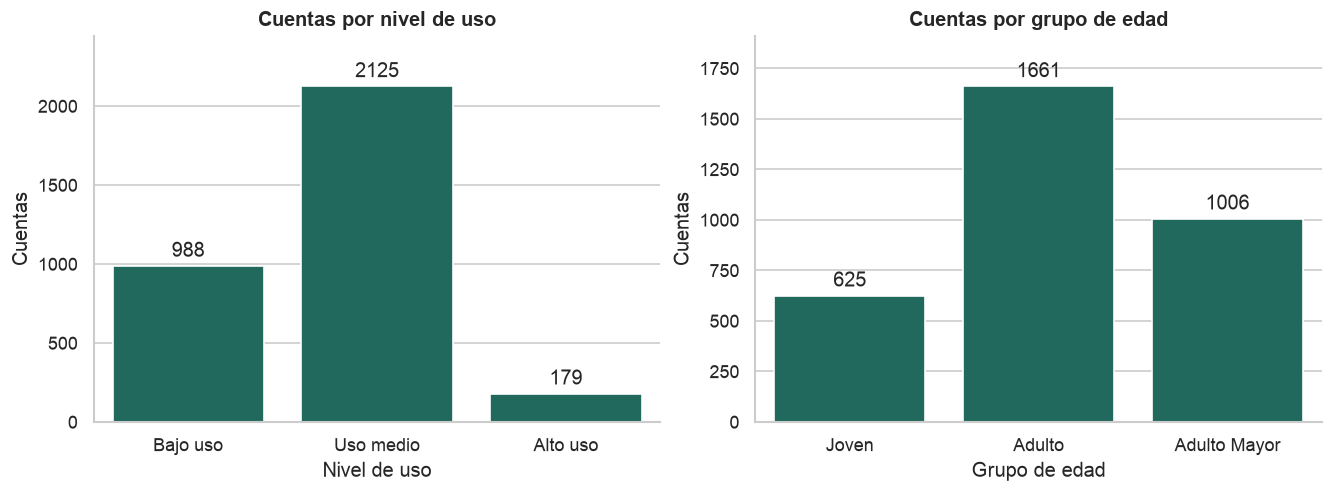

,cant_llamadas,cant_mensajes,cant_minutos_llamada
grupo_edad,,,
Joven,4.0,5.0,16.62
Adulto,4.0,5.0,18.18
Adulto Mayor,4.0,5.0,16.96


,cant_llamadas,cant_mensajes,cant_minutos_llamada
grupo_uso,,,
Bajo uso,2.0,3.0,8.97
Uso medio,5.0,6.0,20.96
Alto uso,5.0,10.0,24.74


grupo_uso,Bajo uso,Uso medio,Alto uso,All
grupo_edad,,,,
Joven,207,390,28,625
Adulto,462,1093,106,1661
Adulto Mayor,319,642,45,1006
All,988,2125,179,3292


In [8]:
usage_order = ['Bajo uso', 'Uso medio', 'Alto uso']
school_age_order = ['Joven', 'Adulto', 'Adulto Mayor']
calls_total, texts_total = user_profile['cant_llamadas'], user_profile['cant_mensajes']
user_profile['grupo_uso'] = pd.Categorical(np.select(
    [calls_total.lt(5) & texts_total.lt(5), calls_total.lt(10) & texts_total.lt(10)],
    usage_order[:2], default=usage_order[2]), categories=usage_order, ordered=True)
user_profile['grupo_edad'] = pd.Categorical(np.select(
    [user_profile['age'].lt(30), user_profile['age'].lt(60)],
    school_age_order[:2], default=school_age_order[2]), categories=school_age_order, ordered=True)
assert user_profile[['grupo_uso', 'grupo_edad']].notna().all().all()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, col, order, label in zip(axes, ['grupo_uso', 'grupo_edad'], [usage_order, school_age_order],
                                  ['nivel de uso', 'grupo de edad']):
    sns.countplot(data=user_profile, x=col, order=order, color=TEAL, ax=ax)
    ax.set(title=f'Cuentas por {label}', xlabel=label.capitalize(), ylabel='Cuentas')
    for bar in ax.containers[0]:
        height = bar.get_height()
        ax.annotate(f'{height:.0f}', (bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom')
    ax.margins(y=.15)
sns.despine(fig=fig)
plt.show()

group_metrics = ['cant_llamadas', 'cant_mensajes', 'cant_minutos_llamada']
groups_by_age = user_profile.groupby('grupo_edad', observed=True)[group_metrics].median()
groups_by_usage = user_profile.groupby('grupo_uso', observed=True)[group_metrics].median()
display(groups_by_age.round(2), groups_by_usage.round(2))
display(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], margins=True))

### 6.2 Comparación con exposición por 30 días

Se usan tramos de edad más estrechos para explorar diferencias y tasas para comparar exposiciones distintas. Las cuentas con tasa cero forman un grupo propio. Entre las que tienen actividad, `Bajo` queda en P25 o menos, `Alto` en P75 o más y `Medio` entre ambos. Los límites son iguales para todos los planes y países.

In [9]:
age_order = ['18–29', '30–44', '45–59', '60+', 'Sin edad']
country_order = ['Colombia', 'México', 'Sin país']
behaviour_order = ['Sin actividad', 'Bajo', 'Medio', 'Alto']


def segment_summary(frame, by):
    summary = frame.groupby(by, observed=True).agg(
        cuentas=('user_id', 'size'), llamadas_30d=('llamadas_30d', 'median'),
        mensajes_30d=('mensajes_30d', 'median'), minutos_30d=('minutos_30d', 'median'),
        minutos_p90=('minutos_30d', lambda col: col.quantile(.90)),
        sin_actividad_pct=('eventos', lambda col: 100 * col.eq(0).mean()),
    )
    return summary.rename(columns={'sin_actividad_pct': '% sin actividad'})


positive = stable.loc[stable['eventos_30d'].gt(0), 'eventos_30d']
usage_q25, usage_q75 = positive.quantile([.25, .75])
stable['uso'] = pd.Categorical(np.select(
    [stable['eventos_30d'].eq(0), stable['eventos_30d'].le(usage_q25), stable['eventos_30d'].ge(usage_q75)],
    ['Sin actividad', 'Bajo', 'Alto'], default='Medio'), categories=behaviour_order, ordered=True)
print(f'Umbrales de actividad por 30 días: P25 = {usage_q25:.2f}, P75 = {usage_q75:.2f}.')

by_age = segment_summary(stable, 'edad_grupo').reindex(age_order)
by_plan = segment_summary(stable, 'plan_label').sort_index()
by_country = segment_summary(stable, 'country').reindex(country_order)
by_usage = segment_summary(stable, 'uso').reindex(behaviour_order)
for title, summary in [('Tramo de edad', by_age), ('Plan contratado', by_plan),
                       ('País derivado', by_country), ('Intensidad de uso', by_usage)]:
    display(Markdown(f'**{title}**'))
    display(summary.round(2))

cross_segments = segment_summary(stable, ['plan_label', 'edad_grupo', 'country'])
display(Markdown('**Cruce de plan, edad y país (solo grupos de al menos 30 cuentas)**'))
display(cross_segments.loc[cross_segments['cuentas'].ge(30)].round(2))

Umbrales de actividad por 30 días: P25 = 1.32, P75 = 1.98.


**Tramo de edad**

,cuentas,llamadas_30d,mensajes_30d,minutos_30d,minutos_p90,% sin actividad
edad_grupo,,,,,,
18–29,603.0,0.66,0.82,3.05,7.16,0.66
30–44,805.0,0.66,0.82,3.19,6.97,0.25
45–59,802.0,0.66,0.83,3.43,7.27,0.37
60+,975.0,0.66,0.82,3.16,7.17,0.41
Sin edad,NaN,NaN,NaN,NaN,NaN,NaN


**Plan contratado**

,cuentas,llamadas_30d,mensajes_30d,minutos_30d,minutos_p90,% sin actividad
plan_label,,,,,,
Básico,2060,0.66,0.82,3.13,7.02,0.44
Premium,1125,0.66,0.82,3.34,7.39,0.36


**País derivado**

,cuentas,llamadas_30d,mensajes_30d,minutos_30d,minutos_p90,% sin actividad
country,,,,,,
Colombia,1476,0.66,0.82,3.19,7.15,0.20
México,1262,0.66,0.82,3.19,7.17,0.63
Sin país,447,0.66,0.85,3.17,7.27,0.45


**Intensidad de uso**

,cuentas,llamadas_30d,mensajes_30d,minutos_30d,minutos_p90,% sin actividad
uso,,,,,,
Sin actividad,13,0.00,0.00,0.00,0.00,100.0
Bajo,1033,0.49,0.66,1.96,4.91,0.0
Medio,1201,0.66,0.99,3.24,6.81,0.0
Alto,938,0.99,1.32,4.72,8.86,0.0


**Cruce de plan, edad y país (solo grupos de al menos 30 cuentas)**

cuentas  llamadas_30d  mensajes_30d  \
plan_label edad_grupo country                                         
Básico     18–29      Colombia      185          0.66          0.82   
                      México        148          0.66          0.82   
                      Sin país       56          0.58          0.82   
           30–44      Colombia      229          0.82          0.82   
                      México        200          0.66          0.82   
                      Sin país       83          0.66          0.99   
           45–59      Colombia      233          0.66          0.98   
                      México        221          0.68          0.82   
                      Sin país       71          0.82          0.82   
           60+        Colombia      303          0.66          0.94   
                      México        253          0.66          0.82   
                      Sin país       78          0.66          0.82   
Premium    18–29      Colombia       95          0.71          0.82   
                      México         90          0.66          0.82   
           30–44      Colombia      139          0.66          0.82   
                      México        115          0.66          0.99   
                      Sin país       39          0.66          0.66   
           45–59      Colombia      138          0.66          0.82   
                      México        108          0.82          0.99   
                      Sin país       31          0.66          0.90   
           60+        Colombia      154          0.66          0.82   
                      México        127          0.82          0.82   
                      Sin país       60          0.68          0.99   

                                minutos_30d  minutos_p90  % sin actividad  
plan_label edad_grupo country                                              
Básico     18–29      Colombia         2.92         7.44             1.08  
                      México           3.17         7.23             0.68  
                      Sin país         2.88         6.61             0.00  
           30–44      Colombia         3.13         7.29             0.00  
                      México           2.91         6.49             1.00  
                      Sin país         2.88         6.01             0.00  
           45–59      Colombia         3.28         7.11             0.43  
                      México           3.79         7.31             0.45  
                      Sin país         3.61         8.86             0.00  
           60+        Colombia         3.14         7.05             0.00  
                      México           2.91         6.83             0.79  
                      Sin país         2.84         7.48             0.00  
Premium    18–29      Colombia         3.07         6.82             0.00  
                      México           3.27         7.21             0.00  
           30–44      Colombia         3.57         7.32             0.00  
                      México           3.14         8.13             0.00  
                      Sin país         3.48         6.52             0.00  
           45–59      Colombia         2.93         6.90             0.00  
                      México           3.57         7.35             0.00  
                      Sin país         4.24         7.90             3.23  
           60+        Colombia         3.44         7.40             0.00  
                      México           3.33         8.00             1.57  
                      Sin país         3.28         7.19             0.00

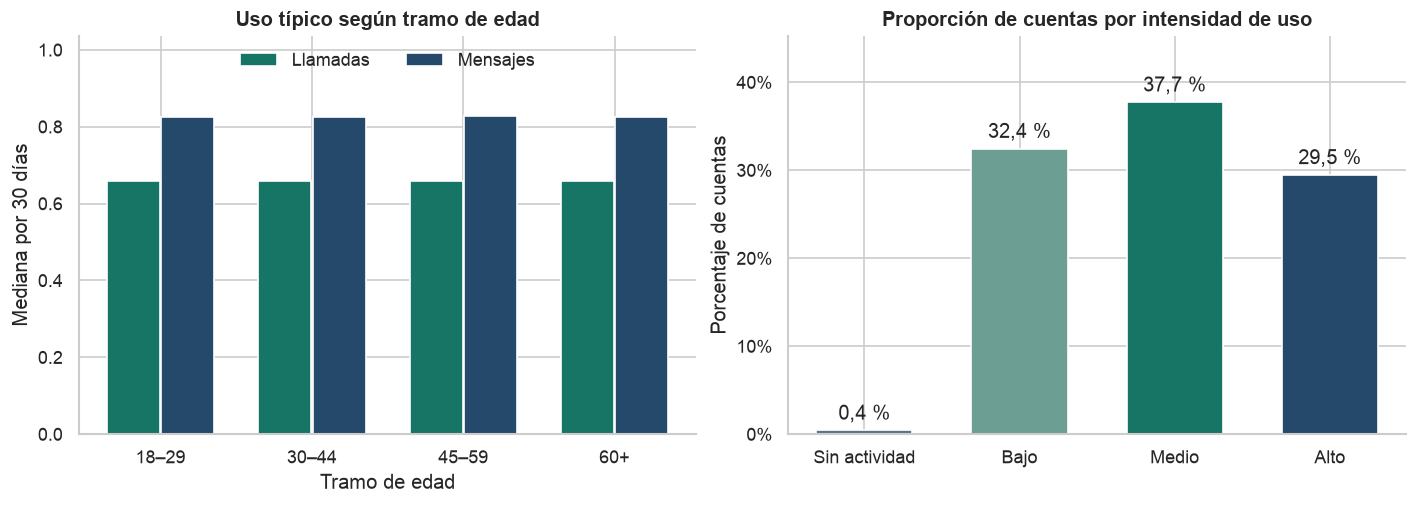

**Intensidad de uso dentro de cada plan (% de las cuentas del plan)**

uso,Sin actividad,Bajo,Medio,Alto
plan_label,,,,
Básico,0.4,33.0,37.4,29.2
Premium,0.4,31.4,38.3,30.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.7, 4.1), constrained_layout=True)
age_plot = by_age.loc[age_order[:-1], ['llamadas_30d', 'mensajes_30d']]
x = np.arange(len(age_plot))
axes[0].bar(x - .18, age_plot['llamadas_30d'], width=.35, color=TEAL, label='Llamadas')
axes[0].bar(x + .18, age_plot['mensajes_30d'], width=.35, color=NAVY, label='Mensajes')
axes[0].set_xticks(x)
axes[0].set_xticklabels(age_plot.index)
axes[0].set(title='Uso típico según tramo de edad', xlabel='Tramo de edad', ylabel='Mediana por 30 días')
axes[0].set_ylim(top=age_plot.max().max() * 1.25)
axes[0].legend(frameon=False, loc='upper center', ncol=2)
usage_pct = 100 * stable['uso'].value_counts(normalize=True).reindex(behaviour_order)
bars = axes[1].bar(usage_pct.index, usage_pct, color=[SLATE, '#6D9E94', TEAL, NAVY], width=.62)
axes[1].set(title='Proporción de cuentas por intensidad de uso', xlabel='', ylabel='Porcentaje de cuentas')
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
axes[1].set_ylim(top=usage_pct.max() * 1.2)
for bar, value in zip(bars, usage_pct):
    axes[1].annotate(f'{value:.1f} %'.replace('.', ','), (bar.get_x() + bar.get_width() / 2, value),
                     xytext=(0, 4), textcoords='offset points', ha='center', va='bottom')
sns.despine(fig=fig, left=False)
plt.show()

display(Markdown('**Intensidad de uso dentro de cada plan (% de las cuentas del plan)**'))
display((100 * pd.crosstab(stable['plan_label'], stable['uso'], normalize='index'))
        .reindex(columns=behaviour_order, fill_value=0).round(1))

### Beneficios del plan y uso mensual

Se comparan minutos y mensajes con el catálogo en los meses completos observables. Junio se excluye de esta comparación porque el extracto termina al inicio del día 30. Se cuentan cuentas elegibles durante todo el mes, con o sin eventos. El plan es el registrado en el padrón y puede haber cambiado históricamente. El uso medido en este extracto no equivale a consumo facturable y no hay eventos de datos móviles para evaluar GB.

In [11]:
calendar = pd.DataFrame({'inicio_mes': pd.date_range(START, END, freq='MS')})
calendar['fin_mes'] = calendar['inicio_mes'] + pd.offsets.MonthEnd(0)
calendar = calendar.loc[calendar['fin_mes'].lt(usage['event_day'].max())]
plan_months = profiles.loc[profiles['plan_match'].eq('both'), ['user_id', 'plan_label', 'observed_start',
                            'observed_end', 'minutes_included', 'messages_included']].merge(calendar, how='cross')
plan_months = plan_months.loc[plan_months['observed_start'].le(plan_months['inicio_mes']) &
                              plan_months['observed_end'].ge(plan_months['fin_mes'])].copy()
events_by_month = events.assign(inicio_mes=events['event_day'].dt.to_period('M').dt.to_timestamp())
monthly_usage = summarize_events(events_by_month, ['user_id', 'inicio_mes']).reset_index()
plan_months = plan_months.merge(monthly_usage, on=['user_id', 'inicio_mes'], how='left', validate='one_to_one')
plan_months[metrics] = plan_months[metrics].fillna(0)
plan_months['supera_minutos'] = plan_months['minutos'].gt(plan_months['minutes_included'])
plan_months['supera_mensajes'] = plan_months['mensajes'].gt(plan_months['messages_included'])
plan_months['supera_alguno'] = plan_months['supera_minutos'] | plan_months['supera_mensajes']
monthly_plan_summary = plan_months.groupby('plan_label', observed=True).agg(
    cuentas_mes=('user_id', 'size'), cuentas_distintas=('user_id', 'nunique'),
    mediana_minutos=('minutos', 'median'), p95_minutos=('minutos', lambda s: s.quantile(.95)),
    mediana_mensajes=('mensajes', 'median'), supera_minutos=('supera_minutos', 'sum'),
    supera_mensajes=('supera_mensajes', 'sum'), supera_alguno=('supera_alguno', 'sum'))
monthly_plan_summary['% supera algún cupo'] = (100 * monthly_plan_summary['supera_alguno'] / monthly_plan_summary['cuentas_mes'])
repeat_exceed = plan_months.groupby(['plan_label', 'user_id'])['supera_alguno'].sum().ge(2)
monthly_plan_summary['cuentas que superan en ≥2 meses'] = repeat_exceed.groupby(level=0).sum()
assert not plan_months.duplicated(['user_id', 'inicio_mes']).any()
assert plan_months['supera_alguno'].sum() == monthly_plan_summary['supera_alguno'].sum()
display(plans[['plan_name', 'usd_monthly_pay', 'minutes_included', 'messages_included', 'gb_per_month']].set_index('plan_name'))
display(monthly_plan_summary.round(2))
print('Meses completos comparados: ' + ', '.join(calendar['inicio_mes'].dt.strftime('%Y-%m')))

,usd_monthly_pay,minutes_included,messages_included,gb_per_month
plan_name,,,,
Básico,12,100,100,5
Premium,25,600,500,20


,cuentas_mes,cuentas_distintas,mediana_minutos,p95_minutos,mediana_mensajes,supera_minutos,supera_mensajes,supera_alguno,% supera algún cupo,cuentas que superan en ≥2 meses
plan_label,,,,,,,,,,
Básico,9232,1989,0.35,16.49,1.0,5,0,5,0.05,0
Premium,5039,1085,0.46,17.22,1.0,0,0,0,0.00,0


Meses completos comparados: 2024-01, 2024-02, 2024-03, 2024-04, 2024-05


## 7. Conclusiones y recomendaciones para ConnectaTel

Las cifras del resumen se generan a partir de las tablas anteriores. Los segmentos se comparan de forma descriptiva; las diferencias pueden reflejar la composición de los grupos, la cobertura del extracto u otros factores no observados.

In [12]:
def es(number, decimals=0):
    return f'{number:,.{decimals}f}'.translate(str.maketrans(',.', '.,'))


calls, texts = (int(events['type'].eq(t).sum()) for t in ('call', 'text'))
early_with_valid_reg = int(audit.loc['Evento anterior al alta', 'eventos'])
early_with_future_reg = int(audit.loc['Alta posterior a 2024', 'eventos'])
early = early_with_valid_reg + early_with_future_reg
known_ages = by_age.loc[age_order[:-1]]
age_range = known_ages[['llamadas_30d', 'mensajes_30d', 'minutos_30d']].agg(['min', 'max']).T
age_readout = []
for label, row in age_range.iterrows():
    measure = label.removesuffix('_30d')
    low, high = es(row['min'], 2), es(row['max'], 2)
    age_readout.append(f'{low} {measure} en cada tramo' if low == high else f'{low}–{high} {measure}')
plan_readout = '; '.join(f'{label}: {es(row.llamadas_30d, 2)} llamadas y {es(row.mensajes_30d, 2)} mensajes'
                         for label, row in by_plan.iterrows())
country_readout = '; '.join(f'{label}: {es(row.llamadas_30d, 2)} llamadas y {es(row.mensajes_30d, 2)} mensajes'
                            for label, row in by_country.drop(index='Sin país').iterrows())
months_over = int(plan_months['supera_alguno'].sum())
months_n = len(plan_months)
repeat_n = int(monthly_plan_summary['cuentas que superan en ≥2 meses'].sum())
duration_iqr = int(diagnostics.at['Duración por llamada', 'IQR'])
duration_z = int(diagnostics.at['Duración por llamada', 'Z'])
segment_difference = by_usage.at['Alto', 'minutos_30d'] - by_usage.at['Bajo', 'minutos_30d']
school_group_counts = user_profile['grupo_uso'].value_counts()
school_readout = ', '.join(f'{key}: {es(school_group_counts.get(key, 0))}' for key in usage_order)
quality_age = int(quality['Edad centinela -999'])
quality_city = int(quality['Ciudad vacía en origen'] + quality['Ciudad centinela ?'])
quality_date = int(reg_out_of_range.sum())

display(Markdown(f"""
### Qué muestran los datos

- **Calidad.** Se imputaron {es(quality_age)} edades con el centinela `-999` ({es(quality_age/len(users)*100, 2)} %). La ciudad faltaba o tenía el centinela `?` en {es(quality_city)} cuentas ({es(quality_city/len(users)*100, 2)} %). Se invalidaron {es(quality_date)} fechas de alta posteriores a 2024 ({es(quality_date/len(users)*100, 2)} %). El patrón de nulos de duración y longitud depende del tipo de evento.
- **Uso y cobertura.** Se conservaron **{es(len(events))} de {es(len(joined))} eventos** ({es(100*len(events)/len(joined), 1)} %), con {es(calls)} llamadas y {es(texts)} mensajes. **{es(early)} eventos** precedían al alta registrada. De ellos, {es(early_with_future_reg)} correspondían a altas posteriores a 2024. El análisis de sensibilidad muestra el efecto de conservar ese historial.
- **Qué segmentos usan más.** Los cortes fijos del proyecto dan {school_readout} cuentas. Al ajustar por exposición, el segmento Alto registra una mediana de **{es(segment_difference, 2)} minutos más por 30 días** que el segmento Bajo. Por edad, las medianas por 30 días fueron {', '.join(age_readout)}. La mediana por plan fue {plan_readout}. Entre cuentas con país identificado: {country_readout}. La intensidad observada separa mejor a los grupos que las medianas por edad, plan o país.
- **Valor para el negocio.** Las cuentas con uso alto persistente son candidatas para probar beneficios de voz o acciones de retención. Para comparar rentabilidad se necesitan ingresos, costos y el historial real de planes.
- **Qué casos revisar.** Al menos un indicador de uso alto señala **{es(len(casos_atipicos))} cuentas**. El IQR marcó {es(duration_iqr)} duraciones de llamada y el puntaje Z marcó {es(duration_z)}. Los umbrales y la tabla de casos permiten reproducir la selección. Las señales estadísticas por sí solas no identifican fraude.
- **Comparación con los planes.** En los meses completos observables, **{es(months_over)} de {es(months_n)} cuentas-mes** ({es(100*months_over/months_n, 2)} %) superaron algún cupo. Hubo {es(plan_months['supera_minutos'].sum())} casos de voz y {es(plan_months['supera_mensajes'].sum())} de mensajes. **{es(repeat_n)} cuentas** superaron algún cupo en dos o más meses. La comparación solo usa actividad registrada y el plan del padrón.

### Decisiones recomendadas

1. **Corregir las fechas antes de usar el análisis para facturación.** Contrastar los {es(early)} eventos anteriores al alta con los sistemas de clientes y de actividad. Incorporar controles de fechas, claves y campos aplicables por tipo de evento al ingreso de datos.
2. **Probar ofertas según uso observado.** Por la baja proporción de meses sobre el cupo, mantener la estructura de planes como punto de partida. Probar paquetes de minutos o alertas de consumo en un grupo pequeño de usuarios con uso alto persistente, y medir excedentes, adopción y retención antes de ampliar el piloto.
3. **Investigar los extremos con evidencias.** Priorizar los casos con varias señales. Revisar si los valores repetidos de duración o longitud corresponden a límites del sistema, eventos válidos o errores de captura. Obtener eventos de datos móviles y el historial de planes antes de recomendar cambios en GB o migraciones comerciales.
"""))


### Qué muestran los datos

- **Calidad.** Se imputaron 55 edades con el centinela `-999` (1,38 %). La ciudad faltaba o tenía el centinela `?` en 565 cuentas (14,12 %). Se invalidaron 40 fechas de alta posteriores a 2024 (1,00 %). El patrón de nulos de duración y longitud depende del tipo de evento.
- **Uso y cobertura.** Se conservaron **29.482 de 40.000 eventos** (73,7 %), con 13.157 llamadas y 16.325 mensajes. **10.431 eventos** precedían al alta registrada. De ellos, 373 correspondían a altas posteriores a 2024. El análisis de sensibilidad muestra el efecto de conservar ese historial.
- **Qué segmentos usan más.** Los cortes fijos del proyecto dan Bajo uso: 988, Uso medio: 2.125, Alto uso: 179 cuentas. Al ajustar por exposición, el segmento Alto registra una mediana de **2,76 minutos más por 30 días** que el segmento Bajo. Por edad, las medianas por 30 días fueron 0,66 llamadas en cada tramo, 0,82–0,83 mensajes, 3,05–3,43 minutos. La mediana por plan fue Básico: 0,66 llamadas y 0,82 mensajes; Premium: 0,66 llamadas y 0,82 mensajes. Entre cuentas con país identificado: Colombia: 0,66 llamadas y 0,82 mensajes; México: 0,66 llamadas y 0,82 mensajes. La intensidad observada separa mejor a los grupos que las medianas por edad, plan o país.
- **Valor para el negocio.** Las cuentas con uso alto persistente son candidatas para probar beneficios de voz o acciones de retención. Para comparar rentabilidad se necesitan ingresos, costos y el historial real de planes.
- **Qué casos revisar.** Al menos un indicador de uso alto señala **185 cuentas**. El IQR marcó 626 duraciones de llamada y el puntaje Z marcó 152. Los umbrales y la tabla de casos permiten reproducir la selección. Las señales estadísticas por sí solas no identifican fraude.
- **Comparación con los planes.** En los meses completos observables, **5 de 14.271 cuentas-mes** (0,04 %) superaron algún cupo. Hubo 5 casos de voz y 0 de mensajes. **0 cuentas** superaron algún cupo en dos o más meses. La comparación solo usa actividad registrada y el plan del padrón.

### Decisiones recomendadas

1. **Corregir las fechas antes de usar el análisis para facturación.** Contrastar los 10.431 eventos anteriores al alta con los sistemas de clientes y de actividad. Incorporar controles de fechas, claves y campos aplicables por tipo de evento al ingreso de datos.
2. **Probar ofertas según uso observado.** Por la baja proporción de meses sobre el cupo, mantener la estructura de planes como punto de partida. Probar paquetes de minutos o alertas de consumo en un grupo pequeño de usuarios con uso alto persistente, y medir excedentes, adopción y retención antes de ampliar el piloto.
3. **Investigar los extremos con evidencias.** Priorizar los casos con varias señales. Revisar si los valores repetidos de duración o longitud corresponden a límites del sistema, eventos válidos o errores de captura. Obtener eventos de datos móviles y el historial de planes antes de recomendar cambios en GB o migraciones comerciales.


## 8. Publicación y reproducibilidad

- Las fuentes son los tres CSV de ConnectaTel entregados por TripleTen. Las huellas SHA-256 del inicio permiten confirmar la versión utilizada.
- El país se deriva de la ciudad. Si la ciudad no permite determinarlo, se usa `Sin país`. Las edades imputadas quedan marcadas en el perfil para medir ese efecto si se necesitan conclusiones por edad.
- El corte cronológico reduce el riesgo de atribuir actividad a una cuenta fuera de su período de servicio, pero también puede excluir actividad real si las fechas administrativas están mal registradas. Por eso se incluye la comparación de sensibilidad.
- La comparación mensual es descriptiva. Faltan el historial de planes, el consumo en GB, las reglas de redondeo y cargos efectivos. No se estiman ingresos ni se infiere causalidad.
- El README describe cómo ejecutar el notebook con los CSV de la lección. Las salidas guardadas omiten los nombres y las claves de las cuentas.

**Repositorio público del proyecto** · [Notebook y README en GitHub](https://github.com/dcamachos199-svg/connectatel-sprint-7)